# A Support Vector Machine

Лекц 8 дээр бид Дэмжигч вектор машины аргыг үзсэн ба энэхүү лабораторийн ажилаар уг аргыг Python хэл дээр өөрсдийн өгөгдөл ашиглан туршин үзэж стандарт сангын аргатай харьцуулах болно. Илүү ихийг мэдэхийг хүсвэл дараах судалгааны ажилуудыг санал болгож байна. Үүнд:

**Schölkopf & Smola** (2002). Learning with Kernels. Support Vector Machines, Regularization, Optimization, and Beyond.

Мөн түүнчлэн, MIT-ийн SVM-ийн математик суурьтай холбоотой товч танилцуулга байдаг.

https://www.google.de/search?client=ubuntu&channel=fs&q=svm+standford&ie=utf-8&oe=utf-8&gfe_rd=cr&ei=UfDhWM_BMunVXredsIgI#q=support+vector+machine+tutorial&channel=fs&start=10&*


✅ Даалгавар 1 — Hinge алдагдлын SGD шинэчлэлт: λ = 1/epoch, гурав дахь шинж нь −1 тул бодит bias нь −w[2].

In [1]:
import numpy as np

X = np.array([
    [-2,4, -1],
    [4, 1, -1],
    [1, 6, -1],
    [2, 4, -1],
    [6, 2, -1],

])

y = np.array([-1,-1,1,1,1])

def svm_sgd(X, Y):

    w = np.zeros(len(X[0]))
    eta = 1
    epochs = 100000


    for epoch in range(1,epochs):
        for i, x in enumerate(X):
            if Y[i] * np.dot(x, w) < 1:
                w += eta * (Y[i] * x - 2 * w / epoch)
            else:
                w += eta * (-2 * w / epoch)


    return w

w = svm_sgd(X,y)
print(w)

[ 1.58876117  3.17458055 11.11863105]


## Сангуудыг дуудаж оруулах

Эхлээд бид python дээр шугаман алгебр болон тооцооллын үйлдлүүдийг хялбар удирдахын тулд numpy-г ашиглах болно. Суралцах явцыг графикаар дүрсэлж харахын тулд бид matplotlib ашиглана.

✅ Даалгавар 1 — Туршилтыг давтахад ижил үр дүн авахын тулд санамсаргүй үрийг тогтоов.

In [2]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
np.random.seed(42)
from IPython.display import display, Markdown

### Stochastic Gradient Descent

Perceptron-ийн хувьд бид python3 болон numpy ашигладаг. SVM нь Stochastic Gradient Descent алгоритм (SGD) ашиглан суралцах болно. Gradient Descent нь зардлын функцийн градиентийг дагаж функцийг багасгадаг. Дэлгэрэнгүй мэдээллийг үзнэ үү:

Wikipedia - stochastic gradient descent

### Calculating the Error

Урьдчилан таамаглах алдааг тооцоолохын тулд эхлээд svm-ийн зорилгын функцийг тодорхойлох хэрэгтэй.

#### Hinge Loss Function

Үүнийг хийхийн тулд бид алдааны функцийг тодорхойлж, таамаглалын алдааг тооцоолох хэрэгтэй. Бид перцептрондоо Hinge алдагдлыг ашиглах болно:

$$c(x, y, f(x)) = (1 - y * f(x))_+$$

$c$ алдагдлын функц юм, $x$ дээж, $y$ label, $f(x)$ таамагласан label.

Энэ нь дараахь зүйлийг хэлнэ.
$$
c(x, y, f(x))=
\begin{cases}
    0,& \text{if } y*f(x)\geq 1\\
    1-y*f(x),              & \text{else}
\end{cases}
$$

Хэрэв y ба f(x) нь тэмдэгт утгатай бол $(+1,-1)$ бодно:

хэрэв алдаа 0 бол, $y*f(x)$ нэмэх, тус тус хоёр утга ижил тэмдэгтэй байна.

алдаа $1-y*f(x)$ бол $y*f(x)$ сөрөг

#### Objective Function

Бид алдагдлын функцийг тодорхойлсон болохоор svm-ийн зорилгын функцийг тодорхойлж болно.

$$\underset{w}{min}\ \lambda\parallel w\parallel^2 + \ \sum_{i=1}^n\big(1-y_i \langle x_i,w \rangle\big)_+$$

Дээрхээс харвал svm-ийн зорилго нь хоёр нэр томъёоноос бүрдэнэ. Эхний нэр томъёо нь тогтмолжуулагч, хоёр дахь нэр томъёо нь алдагдал юм. Зохицуулагч нь ашгийн хэмжээг нэмэгдүүлэх ба алдагдлын хооронд тэнцвэржүүлдэг. Дэлгэрэнгүй мэдээлэл авахын тулд дээр дурдсан Schölkopf & Smola номын зааварчилгааг харна уу.
#### Derive the Objective Function

Энэ функцийг багасгахын тулд бидэнд энэ функцийн градиент хэрэгтэй.

Бидэнд хоёр нэр томъёо байгаа тул ялгахдаа нийлбэрийн дүрмийг ашиглан тэдгээрийг тусад нь удирдах болно.

$$
\frac{\delta}{\delta w_k} \lambda\parallel w\parallel^2 \ = 2 \lambda w_k
$$

$$
\frac{\delta}{\delta w_k} \big(1-y_i \langle x_i,w \rangle\big)_+ \ = \begin{cases}
    0,& \text{if } y_i \langle x_i,w \rangle\geq 1\\
    -y_ix_{ik},              & \text{else}
\end{cases}
$$

Энэ нь буруу ангилсан дээж байгаа гэсэн үг $x_i$, $y_i  тус  тус  \langle x_i,w \rangle \ < \ 1$, бид хоёр нэр томъёоны градиентыг ашиглан жингийн вектор w-г шинэчилнэ. Хэрэв $y_i \langle x_i,w \rangle \geq 1$. Бид w-г зохицуулагчийн градиентаар шинэчилнэ. Дүгнэж хэлэхэд svm-ийн стохастик градиент нь дараах байдалтай байна.

if $y_i⟨x_i,w⟩ < 1$:
$$
w = w + \eta (y_ix_i - 2\lambda w)
$$
else:
$$
w = w + \eta (-2\lambda w)
$$

### Data Set

Эхлээд бид label-тэй өгөгдлийн багцыг тодорхойлох хэрэгтэй.

In [3]:
X = np.array([
    [-2, 4],
    [4, 1],
    [1, 6],
    [2, 4],
    [6, 2]
])

y = np.array([-1,-1,1,1,1])

Хялбар байлгахын тулд бид өгөгдлийн багцад bias нэмнэ:

In [4]:
X = np.array([
    [-2,4,-1],
    [4,1,-1],
    [1, 6, -1],
    [2, 4, -1],
    [6, 2, -1],

])

y = np.array([-1,-1,1,1,1])

Энэхүү жижиг мэдээллийн багц нь $-1$ гэсэн label-тэй хоёр дээж, $+1$ гэсэн label-тэй гурван дээжийг агуулсан. Энэ нь өгөгдлийн багц нь хоёр жишээ анги агуулсан тул бид хоёртын ангиллын асуудалтай байна гэсэн үг юм. Өгөгдлийн багцыг шугаман байдлаар салгах боломжтой графикаар зурцгаая:

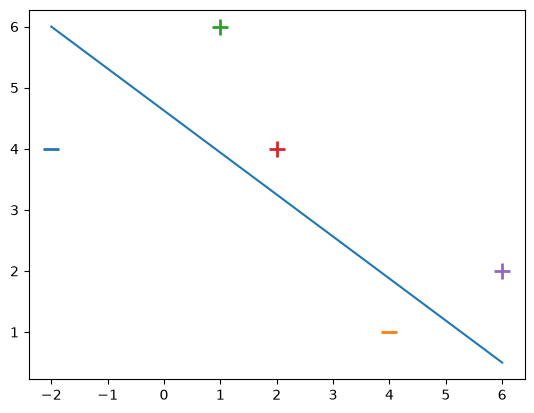

In [5]:
for d, sample in enumerate(X):
    # Сөрөг дээжийг зурах
    if d < 2:
        plt.scatter(sample[0], sample[1], s=120, marker='_', linewidths=2)
    # Эерэг дээжийг зурах
    else:
        plt.scatter(sample[0], sample[1], s=120, marker='+', linewidths=2)

# Хоёр ангийг тусгаарлаж болох hyperplane зурах.
plt.plot([-2,6],[6,0.5])

## Stochastic Gradient Descent

Эцэст нь бид шинэчлэх дүрмээ ашиглан SGD алгоритмаа кодлох боломжтой боллоо. Перцептронуудын зорилгын функцээс эсрэгээр бид алгоритмдаа тогтмолжуулагчийг ашигладаг. Бидэнд шугаман ялгахад хялбар жижиг өгөгдлийн багц байгаа тул энэ нь үнэндээ шаардлагагүй бөгөөд бидний стохастик градиент өгөгдлийн алгоритм үүнгүйгээр илүү хурдан нэгдэх болно.

Энгийн байлгахын тулд бид дээжийн багц дээр шугаман давталт хийнэ. Том өгөгдлийн багцын хувьд for-loop дахь давталт бүрийн үед түүврийг санамсаргүй байдлаар сонгох нь илүү дээр үр дүн гаргах юм.

✅ Даалгавар 1 — Hinge алдагдлын SGD шинэчлэлт: λ = 1/epoch, гурав дахь шинж нь −1 тул бодит bias нь −w[2].

In [6]:
def svm_sgd(X, Y):
    w = np.zeros(len(X[0]))
    eta = 1
    epochs = 100000

    for epoch in range(1,epochs):
        for i, x in enumerate(X):
            if Y[i] * np.dot(x, w) < 1:
                w += eta * (Y[i] * x - 2 * w / epoch)
            else:
                w += eta * (-2 * w / epoch)


    return w

Бид sgd $ 100000$ удаа ажиллуулна. Манай сургалтын параметрийг $1$ гэж тохируулсан. Зохицуулах параметрийн хувьд бид $1/t$-ийг сонгосон тул epoch нэмэгдэх тусам энэ үзүүлэлт буурах болно.

#### Кодын тайлбар Мөр мөрөөр

line <b>2</b>: Перцептроны жингийн векторыг тэгээр эхлүүлнэ<br>
line <b>3</b>: Сурах хурдыг тохируулна уу 1<br>
line <b>4</b>: Epoch тоог тохируулна уу<br>
line <b>6</b>: Бүх өгөгдлийн багцыг n удаа давтана. Тогтворжуулах параметрийг тооцоолохдоо тэг болгон хуваахаас зайлсхийхийн тулд давталт нь $1$-ээс эхэлдэг.<br>
line <b>7</b>: Өгөгдлийн багц дахь дээж бүрийг давтана. <br>
line <b>8</b>: Буруу ангилах нөхцөл $y_i \langle x_i,w \rangle < 1$<br>
line <b>9</b>: Жинг шинэчлэх $w = w + \eta (y_ix_i - 2\lambda w)$ суралцах хурд, $\eta$ болон тогтворжуулагч зэрэг орно $\lambda$<br>
line <b>11</b>: Зөв ангилсан бол жингийн векторыг тогтворжуулагчийн нэр томъёогоор шинэчилнэ $w = w + \eta (-2\lambda w)$.<br>

### SVM-г сурцгаая!

Дараа нь бид сургалтын өгөгдөлд тохирох жингийн векторыг тооцоолохын тулд кодыг ажиллуулж болно. Буруу ангилсан дээж байгаа бол бид буруу ангилсан, зөв ангилсан дээжийн тоог хэвлэх болно.

✅ Даалгавар 1 — Эпох бүрийн дараах буруу ангилсан дээжийн тоо болон hinge зөрчлийн тоог тусад нь харуулав. 🔧 Засвар: анхны кодын догол мөр болон зөвхөн 1 утгыг харуулах y-хязгаарыг засав.

In [7]:
def svm_sgd_plot(X, Y):
    w = np.zeros(X.shape[1])
    eta = 1
    epochs = 100000
    errors, violations = [], []
    for epoch in range(1, epochs):
        error = 0
        for i, x in enumerate(X):
            if Y[i] * np.dot(x, w) < 1:
                w += eta * (Y[i] * x - 2 * w / epoch)
                error += 1
            else:
                w += eta * (-2 * w / epoch)
        violations.append(error)
        errors.append(np.count_nonzero(Y * (X @ w) <= 0))
    plt.plot(errors, label='Misclassified')
    plt.plot(violations, alpha=0.6, label='Hinge violations')
    plt.xlabel('Epoch')
    plt.ylabel('Samples')
    plt.legend()
    plt.show()
    return w


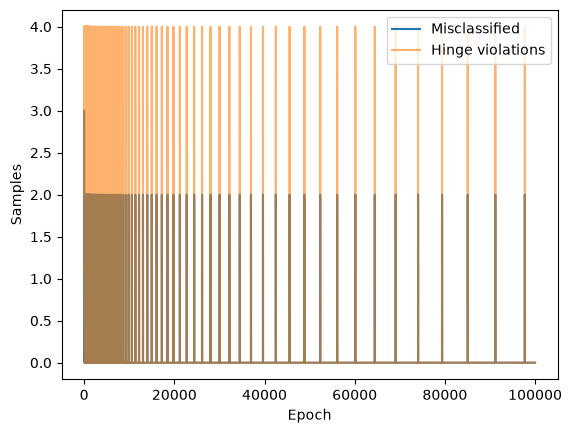

In [8]:
w_plot = svm_sgd_plot(X,y)
assert np.allclose(w_plot, w)

🔧 Засвар: буруу ангилалт (margin ≤ 0) ба hinge зөрчил (margin < 1) хоёр өөр хэмжигдэхүүн. Графикт хоёуланг харуулсан тул тайлбарыг ялгав.

Графикийн Misclassified нь эпохын эцсийн буруу ангилсан дээжийн тоо, Hinge violations нь онлайн шинэчлэлтийн үед y⟨x,w⟩ < 1 болсон тоо юм. Бүх дээж зөв ангилагдсан ч захын нөхцөл зөрчигдөж болно. Тогтмолжуулагч нь жинг агшаадаг тул hinge зөрчил бүрмөсөн алга болох албагүй. λ=1/epoch нь тогтмол биш тул энэ туршилт нэг тогтмол зорилгын яг оновчтой шийдэл гэсэн баталгаа өгөхгүй.

🔧 Засвар: жингийн хуучин тоог зорилтот утга гэж үзээгүй; бодит ажиллуулалтын жин, bias болон оноог доор хэвлэв.

SGD-ийн шийдвэрийн функц нь $f(x)=w_0x_0+w_1x_1-w_2$. Оролтын гурав дахь утга −1 тул bias нь **−w[2]** болно. Доорх үр дүн нь энэ ажиллуулалтын бодит тооцоо юм.

🔧 Засвар: гараар бичсэн, тоймлосон жинтэй тооцоог бодит жинд тулгуурласан давтагдах шалгалтаар сольсон.

Таван сургалтын болон хоёр шинэ дээжийн шийдвэрийн оноог бодит жингээр тооцъё. Онооны тэмдэг нь ангиллыг тодорхойлно; энэ нь сургалтын нарийвчлал бөгөөд ерөнхий тестийн үнэлгээ биш.

✅ Даалгавар 1 — Бодит жин, шалгалт ба дүгнэлт

In [9]:
import pandas as pd
scores = X @ w
extra = np.array([[2, 2, -1], [4, 3, -1]])
print('w =', w, 'bias =', -w[2])
display(pd.DataFrame({'y': y, 'score': scores, 'pred': np.sign(scores)}))
print('Шинэ дээжийн оноо:', extra @ w, 'ангилал:', np.sign(extra @ w))
assert np.array_equal(np.sign(scores), y)
assert np.array_equal(np.sign(extra @ w), [-1, 1])
from sklearn.svm import SVC
linear_check = SVC(kernel='linear', C=1000).fit(X[:, :2], y)
assert np.array_equal(linear_check.predict(X[:, :2]), np.sign(scores))
display(Markdown(f'Сургалтын 5/5, шинэ 2/2 дээж зөв ангилагдав. Жин нь ({w[0]:.5f}, {w[1]:.5f}, {w[2]:.5f}), бодит bias = {-w[2]:.5f}. sklearn-ийн шугаман SVM мөн эдгээр сургалтын дээжийг зөв ангилсан; жин заавал ижил байх албагүй.'))

w = [ 1.58876117  3.17458055 11.11863105] bias = -11.118631048904986


,y,score,pred
0,-1,-1.597831,-1.0
1,-1,-1.589006,-1.0
2,1,9.517613,1.0
3,1,4.757213,1.0
4,1,4.763097,1.0


Шинэ дээжийн оноо: [-1.59194761  4.76015528] ангилал: [-1.  1.]


Сургалтын 5/5, шинэ 2/2 дээж зөв ангилагдав. Жин нь (1.58876, 3.17458, 11.11863), бодит bias = -11.11863. sklearn-ийн шугаман SVM мөн эдгээр сургалтын дээжийг зөв ангилсан; жин заавал ижил байх албагүй.

🔧 Засвар: quiver нь салгах шулууныг зөв зурахгүй, X/y нэрийг дарж байсан. Бодит f(x)=0 шулуун ба ±1 захын шугамыг зурж, өгөгдлийн нэрийг хадгалав.

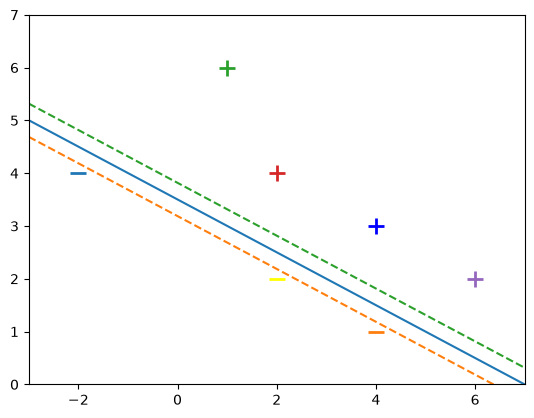

In [10]:
w = svm_sgd(X, y)
for d, sample in enumerate(X):
    # Сөрөг дээжийг зурах
    if d < 2:
        plt.scatter(sample[0], sample[1], s=120, marker='_', linewidths=2)
    # Эерэг дээжийг зурах
    else:
        plt.scatter(sample[0], sample[1], s=120, marker='+', linewidths=2)

# Туршилтын дээжийг нэмнэх

plt.scatter(2,2, s=120, marker='_', linewidths=2, color='yellow')
plt.scatter(4,3, s=120, marker='+', linewidths=2, color='blue')

# Бодит салгах шулуун ба захын шугам
xx_line = np.linspace(-3, 7, 100)
for level, style in [(0, '-'), (-1, '--'), (1, '--')]:
    plt.plot(xx_line, (w[2] + level - w[0] * xx_line) / w[1], style)
plt.xlim(-3, 7)
plt.ylim(0, 7)
plt.show()


🔧 Засвар: bias нь геометрийн нормд орохгүй. Нэг талын захын зай = 1/||w[:2]||, бүтэн өргөн нь үүний хоёр дахин их.

In [11]:
print('Нэг талын захын зай:', 1/np.linalg.norm(w[:2], 2))
print('Бүтэн захын өргөн:', 2/np.linalg.norm(w[:2], 2))
print('Хамгийн ойрын дээжийн тэмдэгтэй зай:', np.min(y*(X@w))/np.linalg.norm(w[:2]))

Нэг талын захын зай: 0.28169434616522265
Бүтэн захын өргөн: 0.5633886923304453
Хамгийн ойрын дээжийн тэмдэгтэй зай: 0.44761395738033327


# Даалгавар 1: Кодын хэсгийг нөхөх

# SVM Kernel

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as pltcolors
from sklearn import linear_model, svm, discriminant_analysis, metrics
from scipy import optimize
import seaborn as sns

🔧 Засвар: support векторын проекцын зайг нормоор хуваах ёстой; үржүүлсэн болон хаалт дутсан томьёог засав.

In [13]:
def plotLine(ax, xRange, w, x0, label, color='grey', linestyle='-', alpha=1.):
    """ Plot a (separating) line given the normal vector (weights) and point of intercept """
    if type(x0) == int or type(x0) == float or type(x0) == np.float64:
        x0 = [0, -x0 / w[1]]
    yy = -(w[0] / w[1]) * (xRange - x0[0]) + x0[1]
    ax.plot(xRange, yy, color=color, label=label, linestyle=linestyle)

def plotSvm(X, y, support=None, w=None, intercept=0., label='Data', separatorLabel='Separator',
            ax=None, bound=[[-1., 1.], [-1., 1.]]):
    """ Plot the SVM separation, and margin """
    if ax is None:
        fig, ax = plt.subplots(1)

    im = ax.scatter(X[:,0], X[:,1], c=y, cmap=cmap, alpha=0.5, label=label)
    if support is not None:
        ax.scatter(support[:,0], support[:,1], label='Support', s=80, facecolors='none',
                   edgecolors='y', color='y')
        print("Number of support vectors = %d" % (len(support)))
    if w is not None:
        xx = np.array(bound[0])
        plotLine(ax, xx, w, intercept, separatorLabel)
        # Захын зайг дүрслэх
        if support is not None:
            signedDist = np.matmul(support, w)
            margin = (np.max(signedDist) - np.min(signedDist)) / np.linalg.norm(w)
            supportMaxNeg = support[np.argmin(signedDist)]
            plotLine(ax, xx, w, supportMaxNeg, 'Margin -', linestyle='-.', alpha=0.8)
            supportMaxPos = support[np.argmax(signedDist)]
            plotLine(ax, xx, w, supportMaxPos, 'Margin +', linestyle='--', alpha=0.8)
            ax.set_title('Margin = %.3f' % (margin))
    ax.legend(loc='upper left')
    ax.grid()
    ax.set_xlim(bound[0])
    ax.set_ylim(bound[1])
    cb = plt.colorbar(im, ax=ax)
    loc = np.arange(-1,1,1)
    cb.set_ticks(loc)
    cb.set_ticklabels(['-1','1'])

🔧 Засвар: хуучин seaborn хувилбарт зориулсан ylim нөхөөс одоогийн heatmap-ын захын мөрийг тайрдаг тул яг матрицын хэмжээгээр тохируулав.

In [14]:
def plotHeatMap(X, classes, title=None, fmt='.2g', ax=None, xlabel=None, ylabel=None):
    """ Fix heatmap plot from Seaborn with pyplot 3.1.0, 3.1.1
        https://stackoverflow.com/questions/56942670/matplotlib-seaborn-first-and-last-row-cut-in-half-of-heatmap-plot
    """
    ax = sns.heatmap(X, xticklabels=classes, yticklabels=classes, annot=True, \
                     fmt=fmt, cmap=plt.cm.Blues, ax=ax)
    bottom, top = ax.get_ylim()
    ax.set_ylim(X.shape[0], 0)
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)

def plotConfusionMatrix(yTrue, yEst, classes, title=None, fmt='.2g', ax=None):
    plotHeatMap(metrics.confusion_matrix(yTrue, yEst), classes, title, fmt, ax, xlabel='Estimations', \
                ylabel='True values');

In [15]:
def generateBatchXor(n, mu=0.5, sigma=0.5):
    """ Four gaussian clouds in a Xor fashion """
    X = np.random.normal(mu, sigma, (n, 2))
    yB0 = np.random.uniform(0, 1, n) > 0.5
    yB1 = np.random.uniform(0, 1, n) > 0.5
    y0 = 2. * yB0 - 1
    y1 = 2. * yB1 - 1
    X[:,0] *= y0
    X[:,1] *= y1
    X -= X.mean(axis=0)
    return X, y0*y1

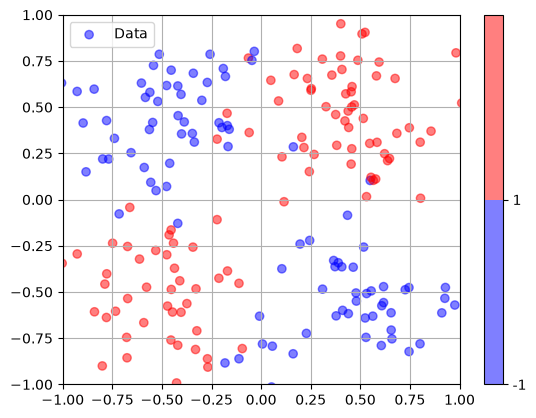

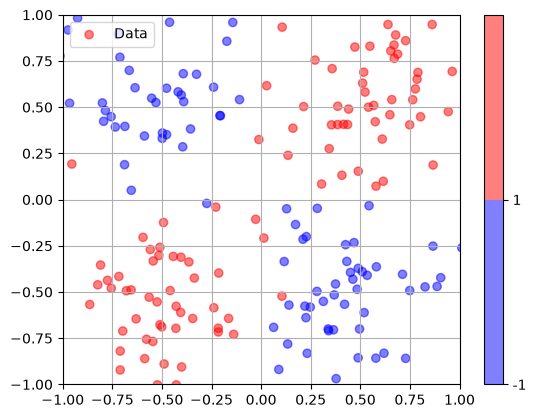

In [16]:
colors = ['blue','red']
cmap = pltcolors.ListedColormap(colors)
nFeatures = 2
N = 100
xTrain, yTrain = generateBatchXor(2*N, sigma=0.25)
plotSvm(xTrain, yTrain)
xTest, yTest = generateBatchXor(2*N, sigma=0.25)
plotSvm(xTest, yTest)

## Kernel trick танилцуулга

Регресс гэх мэт шугаман тусгаарлагчийг ашиглах үед шугаман бус функцийг шийдвэрлэх уламжлалт арга бол анхны шинж чанаруудын зэрэгт болон үржвэрүүдийг ашиглан функцын орон зайг өргөжүүлэх явдал юм.

Шугаман арганд хязгаарлалт бий. Жишээлбэл, XOR асуудлыг зөв шийдвэрийн муж гаргаагүй байна.

SVM нь "Kernel trick" гэгддэг шинэ аргыг ашигласан.

$h(x)$ функцийг ашиглан $x$-д хувиргалтыг хэрэгжүүлцгээе.

Лагранж (Вольф) давхар (хос) асуудал дараах байдалтай байна.
$$\begin{align}
\mathcal{L}_d (\alpha)
&= \sum_{i=0}^n \alpha_i - \frac 12 \sum_{i=0}^n \sum_{k=0}^n \alpha_i \alpha_k y_i y_k h(x_i)^T h(x_k) \\
&= \sum_{i=0}^n \alpha_i - \frac 12 \sum_{i=0}^n \sum_{k=0}^n \alpha_i \alpha_k \langle y_i h(x_i), y_k  h(x_k) \rangle \\
\end{align}$$

__Subject to $\forall i\in 1..n$:__
- $0 \le \alpha_i \le C$
- $\sum_{i=0}^n \alpha_i y_i = 0$

$ w = \sum_{i=0}^n \alpha_i y_i h(x_i)$ тул таамаглах функц байна:
$$ f(x) = sign(w^T h(x) + b) = sign \left(\sum_{i=0}^n \alpha_i y_i \langle h(x_i), h(x) \rangle \right) $$

Энэ таамаглалыг дэмжих вектор болох $\alpha_i > 0$-д тооцоолох шаардлагатай.

Тохиромжтой болон таамаглал хоёулаа Kernel функц гэгддэг $K(x, x') = \langle h(x), h(x') \rangle$ дотоод бүтээгдэхүүн дээр суурилдаг. Энэ функц нь тэгш хэмтэй, хагас тодорхой байна.

Gaussian Radial Basis Function (RBF) : $K(x, x') = exp(- \gamma \Vert x - x' \Vert^2 )$

🔧 Засвар: kernel SVM-д bias дутсан тул чөлөөт support векторын KKT нөхцөлөөр b-г тооцов. Оновчлол амжилтгүй бол ил тод алдаа өгнө; олон ангилалд хэрэглэх тасралтгүй decision_function нэмэв. Чөлөөт support векторгүй үед bound векторуудын equality-bias-ийг дундажлах нь буруу: α=0 үед y(f+b)≥1, α=C үед y(f+b)≤1 нөхцөлөөс b-ийн [L,U] завсрыг гаргаж дундах утгыг сонгоно. Тоон алдаанаас L>U зөрүү 1e−5·max(1,|L|,|U|)-ээс бага бол midpoint хэрэглэж тэр хэмжээнд үлдэгдлийг зөвшөөрнө; илүү зөрвөл алдаа өгнө. Нэг талын хязгаарт тухайн төгсгөлийг авна. None нь энд сургахаас өмнөх төлөв юм.

In [17]:
class KernelSvmClassifier:

    def __init__(self, C, kernel):
        self.C = C
        self.kernel = kernel          # <---
        self.alpha = None
        self.supportVectors = None

    def fit(self, X, y):
        N = len(y)
        # --->
        # h(x) y -ийн Gram matrix
        hXX = np.apply_along_axis(lambda x1 : np.apply_along_axis(lambda x2:  self.kernel(x1, x2), 1, X),
                                  1, X)
        yp = y.reshape(-1, 1)
        GramHXy = hXX * np.matmul(yp, yp.T)
        # <---

        # Lagrange давхар асуудал
        def Ld0(G, alpha):
            return alpha.sum() - 0.5 * alpha.dot(alpha.dot(G))

        # алфа дээрх Лд-ийн хэсэгчилсэн уламжлал
        def Ld0dAlpha(G, alpha):
            return np.ones_like(alpha) - alpha.dot(G)

        # Хэлбэрийн альфа дээрх хязгаарлалт :
        # -  d - C*alpha  = 0
        # -  b - A*alpha >= 0
        A = np.vstack((-np.eye(N), np.eye(N)))             # <---
        b = np.hstack((np.zeros(N), self.C * np.ones(N)))  # <---
        constraints = ({'type': 'eq',   'fun': lambda a: np.dot(a, y),     'jac': lambda a: y},
                       {'type': 'ineq', 'fun': lambda a: b - np.dot(A, a), 'jac': lambda a: -A})

        # Эсрэгээр нь багасгах замаар дээд зэргээр нэмэгдүүлэх
        optRes = optimize.minimize(fun=lambda a: -Ld0(GramHXy, a),
                                   x0=np.ones(N),
                                   method='SLSQP',
                                   jac=lambda a: -Ld0dAlpha(GramHXy, a),
                                   constraints=constraints,
                                   options={"maxiter": 2000, "ftol": 1e-9})
        assert optRes.success, optRes.message
        self.alpha = optRes.x
        # --->
        epsilon = 1e-6
        supportIndices = self.alpha > epsilon
        self.supportVectors = X[supportIndices]
        self.supportAlphaY = y[supportIndices] * self.alpha[supportIndices]
        # <---

        free = (self.alpha > epsilon) & (self.alpha < self.C - epsilon)
        if free.any():
            self.intercept = np.mean(y[free] - hXX[free] @ (self.alpha * y))
        else:
            score_without_bias = hXX @ (self.alpha * y)
            at_zero = self.alpha <= epsilon
            at_C = self.alpha >= self.C - epsilon
            # y=+1, α=0 эсвэл y=-1, α=C үед b ≥ y-f.
            lower_mask = (at_zero & (y > 0)) | (at_C & (y < 0))
            # y=-1, α=0 эсвэл y=+1, α=C үед b ≤ y-f.
            upper_mask = (at_zero & (y < 0)) | (at_C & (y > 0))
            thresholds = y - score_without_bias
            lower = np.max(thresholds[lower_mask], initial=-np.inf)
            upper = np.min(thresholds[upper_mask], initial=np.inf)
            self.intercept_bounds = (lower, upper)
            if np.isfinite(lower) and np.isfinite(upper):
                tolerance = 1e-5 * max(1., abs(lower), abs(upper))
                assert lower <= upper + tolerance, "KKT bias bounds inconsistent"
                self.intercept = (lower + upper) / 2
            elif np.isfinite(lower):
                self.intercept = lower
            elif np.isfinite(upper):
                self.intercept = upper
            else:
                self.intercept = 0.

        self.fit_y = y.copy()
        assert abs(self.alpha @ y) < 1e-5
        assert self.alpha.min() >= -1e-6 and self.alpha.max() <= self.C + 1e-6

    def decision_function(self, X):
        K = np.array([[self.kernel(s, x) for s in self.supportVectors] for x in X])
        return K @ self.supportAlphaY + self.intercept

    def predict(self, X):
        """ Predict y values in {-1, 1} """
        return np.where(self.decision_function(X) > 0, 1, -1)


In [18]:
def GRBF(x1, x2):
    diff = x1 - x2
    return np.exp(-np.dot(diff, diff) * len(x1) / 2)



model30 = KernelSvmClassifier(C=5, kernel=GRBF)
model30.fit(xTrain, yTrain)

# Даалгавар 2: нэмэлт 2 Kernel хэрэгжүүлэх аргын кодыг бичиж туршин үр дүнг харьцуулах

✅ Даалгавар 2 — Шугаман ба 2-р зэргийн polynomial kernel. Шугаман kernel нь XOR-ийн шугаман бус байдлыг илтгэх суурь; polynomial нь x₁x₂ харилцан үйлчлэлийг илэрхийлнэ.

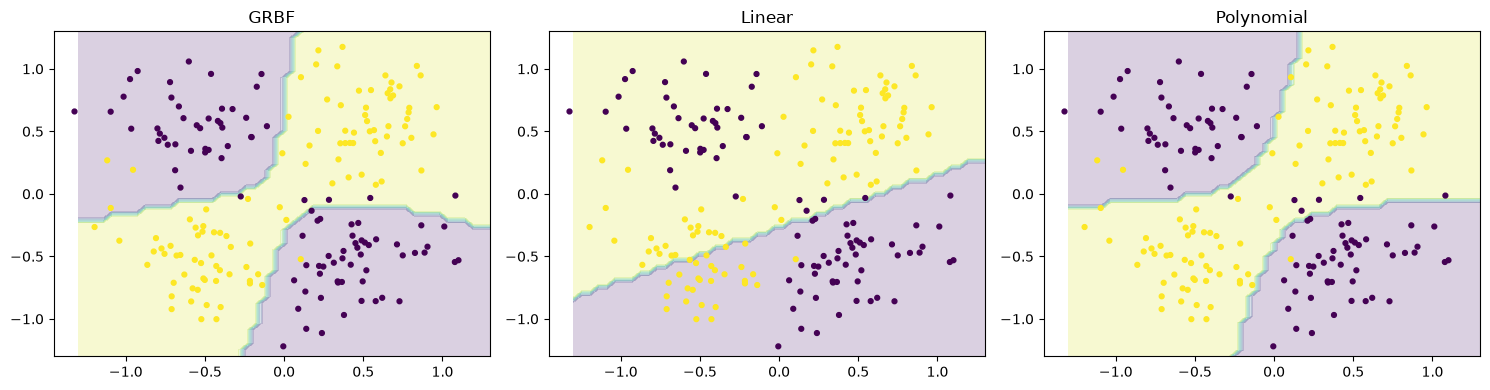

In [19]:
def linear_kernel(a, b):
    return np.dot(a, b)

def polynomial_kernel(a, b):
    return (1 + np.dot(a, b)) ** 2

kernel_models = {'GRBF': model30}
for name, kernel in [('Linear', linear_kernel), ('Polynomial', polynomial_kernel)]:
    kernel_models[name] = KernelSvmClassifier(C=5, kernel=kernel)
    kernel_models[name].fit(xTrain, yTrain)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
g0, g1 = np.meshgrid(np.linspace(-1.3, 1.3, 50), np.linspace(-1.3, 1.3, 50))
grid_kernel = np.c_[g0.ravel(), g1.ravel()]
for ax, (name, classifier) in zip(axes, kernel_models.items()):
    ax.contourf(g0, g1, classifier.predict(grid_kernel).reshape(g0.shape), alpha=0.2)
    ax.scatter(xTest[:, 0], xTest[:, 1], c=yTest, s=12)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Number of support vectors = 47


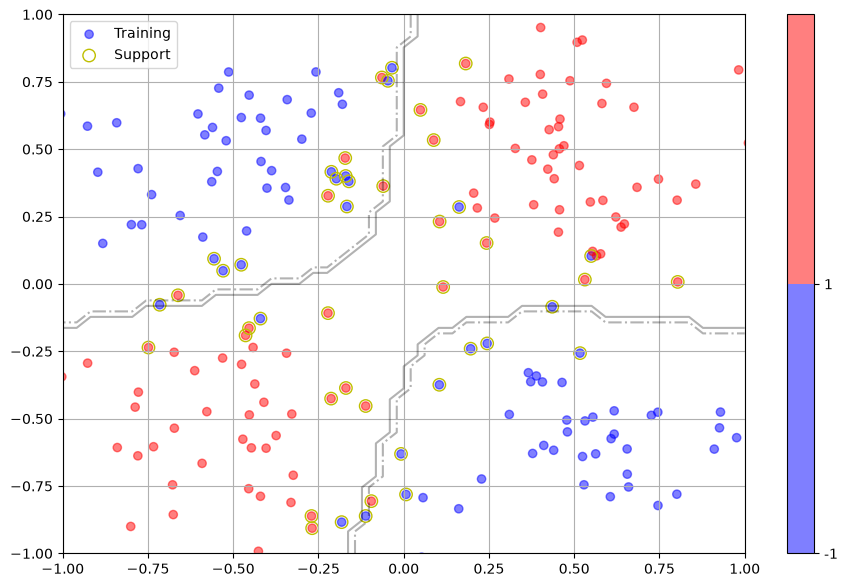

In [20]:
fig, ax = plt.subplots(1, figsize=(11, 7))
plotSvm(xTrain, yTrain, support=model30.supportVectors, label='Training', ax=ax)

# Тооцоолол, шийдвэрийн хил хязгаар
xx = np.linspace(-1, 1, 50)
X0, X1 = np.meshgrid(xx, xx)
xy = np.vstack([X0.ravel(), X1.ravel()]).T
Y30 = model30.predict(xy).reshape(X0.shape)
ax.contour(X0, X1, Y30, colors='k', levels=[-1, 0], alpha=0.3, linestyles=['-.', '-']);

## Scikit Learn SVM with Radial basis kernel

In [21]:
model31 = svm.SVC(kernel='rbf', C=10, gamma=1/2, shrinking=False)
model31.fit(xTrain, yTrain)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.5
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",False
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Number of support vectors = 50


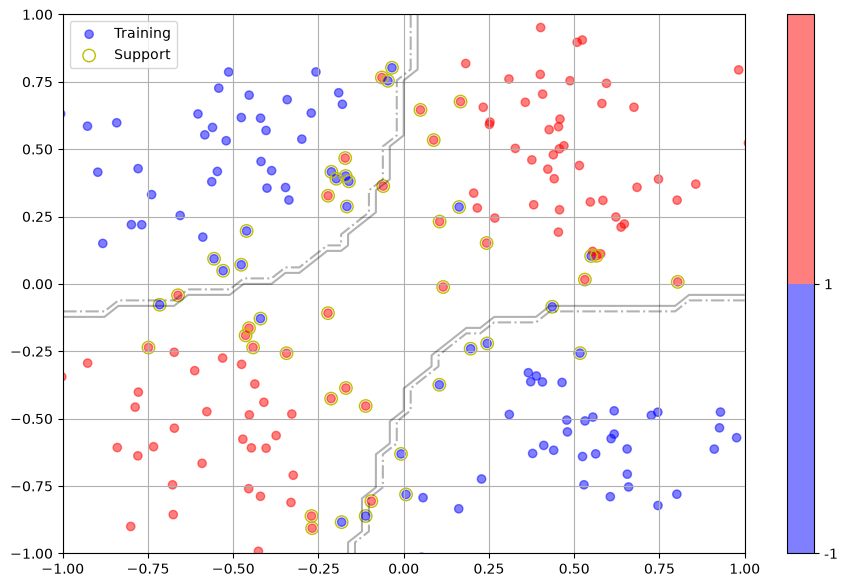

In [22]:
fig, ax = plt.subplots(1, figsize=(11, 7))
plotSvm(xTrain, yTrain, support=model31.support_vectors_, label='Training', ax=ax)

# Тооцоолол, шийдвэрийн хил хязгаар
Y31 = model31.predict(xy).reshape(X0.shape)
ax.contour(X0, X1, Y31, colors='k', levels=[-1, 0], alpha=0.3, linestyles=['-.', '-']);

### SVM with RBF performance on XOR

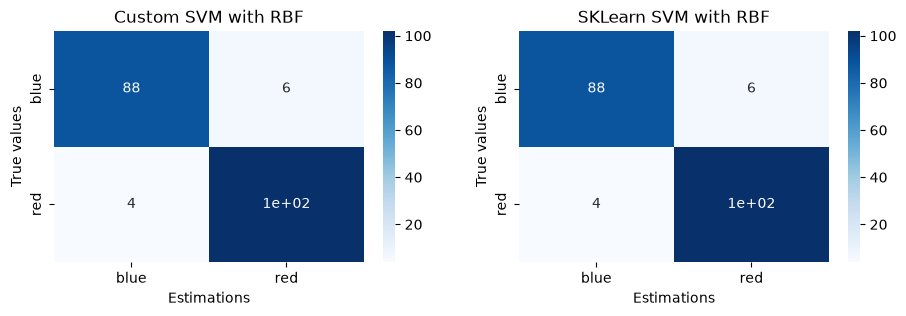

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for model, ax, title in zip([model30, model31], axes, ["Custom SVM with RBF", "SKLearn SVM with RBF"]):
    yEst3 = model.predict(xTest)
    plotConfusionMatrix(yTest, yEst3, colors, title, ax=ax)

Хоёр загварын таамаглал XOR жишээн дээр бараг таарч байна.

✅ Даалгавар 2 — Ижил kernel/параметртэй sklearn шалгалт, тестийн accuracy ба төөрөгдлийн матриц

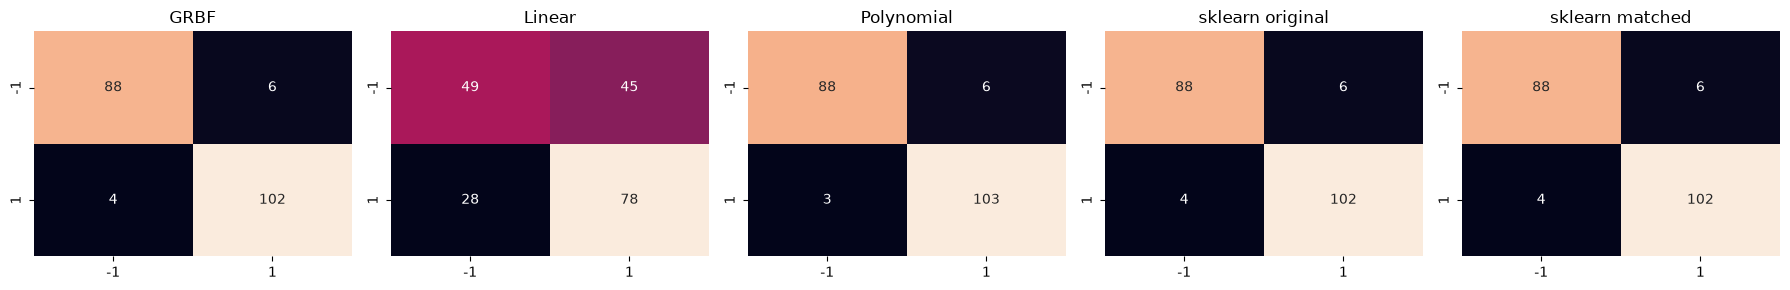

,model,accuracy
0,GRBF,0.950
1,Linear,0.635
2,Polynomial,0.955
3,sklearn original,0.950
4,sklearn matched,0.950


Энэ хуваалтад хамгийн өндөр accuracy: **Polynomial = 0.955**. Шугаман kernel: 0.635; polynomial: 0.955; GRBF: 0.950. XOR-ийн харилцан үйлчлэлийг шугаман бус kernel илэрхийлж байна. Ижил C=5, γ=1 тохиргоотой sklearn ба өөрийн GRBF таамаглалын тохирол 1.000.

In [24]:
matched_svc = SVC(C=5, kernel='rbf', gamma=1).fit(xTrain, yTrain)
comparisons = dict(kernel_models, **{'sklearn original': model31, 'sklearn matched': matched_svc})
rows = []
fig, axes = plt.subplots(1, len(comparisons), figsize=(18, 3))
for ax, (name, classifier) in zip(axes, comparisons.items()):
    prediction = classifier.predict(xTest)
    rows.append({'model': name, 'accuracy': metrics.accuracy_score(yTest, prediction)})
    sns.heatmap(metrics.confusion_matrix(yTest, prediction, labels=[-1, 1]), annot=True,
                fmt='d', cbar=False, ax=ax, xticklabels=[-1, 1], yticklabels=[-1, 1])
    ax.set_title(name)
plt.tight_layout()
plt.show()
results_kernel = pd.DataFrame(rows)
display(results_kernel)
agreement = np.mean(model30.predict(xTest) == matched_svc.predict(xTest))
assert agreement >= 0.98
best_row = results_kernel.iloc[results_kernel.accuracy.argmax()]
display(Markdown(f'Энэ хуваалтад хамгийн өндөр accuracy: **{best_row["model"]} = {best_row.accuracy:.3f}**. Шугаман kernel: {rows[1]["accuracy"]:.3f}; polynomial: {rows[2]["accuracy"]:.3f}; GRBF: {rows[0]["accuracy"]:.3f}. XOR-ийн харилцан үйлчлэлийг шугаман бус kernel илэрхийлж байна. Ижил C=5, γ=1 тохиргоотой sklearn ба өөрийн GRBF таамаглалын тохирол {agreement:.3f}.'))

✅ Даалгавар 2 — Шилжсэн, тэгш хэмгүй өгөгдөл дээр bias-ийн бие даасан шалгалт

In [25]:
shift_X = np.array([[1.,1.], [1.2,1.], [1.,1.4], [3.,2.], [3.4,2.2], [4.,3.]])
shift_y = np.array([-1.,-1.,-1.,1.,1.,1.])
shift_custom = KernelSvmClassifier(C=5, kernel=linear_kernel)
shift_custom.fit(shift_X, shift_y)
shift_ref = SVC(C=5, kernel='linear', tol=1e-8).fit(shift_X, shift_y)
np.testing.assert_allclose(shift_custom.decision_function(shift_X), shift_ref.decision_function(shift_X), atol=1e-4)
assert abs(shift_custom.intercept) > 0.1
for k in [GRBF, linear_kernel, polynomial_kernel]:
    gram_check = np.array([[k(a,b) for b in shift_X] for a in shift_X])
    np.testing.assert_allclose(gram_check, gram_check.T)
    assert np.linalg.eigvalsh(gram_check).min() > -1e-8
print('Шилжсэн өгөгдлийн bias:', shift_custom.intercept, 'sklearn:', shift_ref.intercept_[0])

Шилжсэн өгөгдлийн bias: -2.478289406846208 sklearn: -2.4782606350451486


# Даалгавар 3: Олон ангилалт SVM хэрэгжүүлэх алгоритмыг гүйцэтгэх

✅ Даалгавар 3 — Нэгийн эсрэг бусад (OvR) олон ангилалт SVM

K ангилал бүрт +1/−1 хоёртын SVM сургаж, хамгийн их decision_function оноотой ангийг сонгоно. Ангийн шошго биш тасралтгүй оноог харьцуулна.

In [26]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
Xm, ym = make_blobs(n_samples=150, centers=3, cluster_std=1.1, random_state=42)
Xm = Xm / 5
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.3, stratify=ym, random_state=42)
classes_multi = np.unique(ym_train)
models_multi = []
for cls in classes_multi:
    binary = KernelSvmClassifier(C=5, kernel=GRBF)
    binary.fit(Xm_train, np.where(ym_train == cls, 1., -1.))
    models_multi.append(binary)
pred_multi = classes_multi[np.column_stack([m.decision_function(Xm_test) for m in models_multi]).argmax(axis=1)]
reference_multi = OneVsRestClassifier(SVC(C=5, gamma=1, kernel='rbf')).fit(Xm_train, ym_train)
acc_multi = metrics.accuracy_score(ym_test, pred_multi)
acc_multi_ref = reference_multi.score(Xm_test, ym_test)
print('OvR accuracy:', acc_multi, 'sklearn OvR:', acc_multi_ref)
print(metrics.confusion_matrix(ym_test, pred_multi))
assert np.mean(pred_multi == reference_multi.predict(Xm_test)) >= 0.95
display(Markdown(f'Өөрийн OvR тестийн accuracy **{acc_multi:.3f}**, sklearn OvR **{acc_multi_ref:.3f}**. 3 хоёртын загварын оноогоор 3 ангийг ялгалаа. Энэ нь жижиг синтетик өгөгдлийн үр дүн тул бодит өгөгдөлд шууд ерөнхийлөхгүй.'))

OvR accuracy: 1.0 sklearn OvR: 1.0
[[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]


Өөрийн OvR тестийн accuracy **1.000**, sklearn OvR **1.000**. 3 хоёртын загварын оноогоор 3 ангийг ялгалаа. Энэ нь жижиг синтетик өгөгдлийн үр дүн тул бодит өгөгдөлд шууд ерөнхийлөхгүй.

## Дүгнэлт

Шугаман салгах боломжгүй асуудлуудад зориулсан SVM ангилагчийн хүчийг бид харуулсан. 1990-ээд оны сүүлчээс эхлэн SVM нь олон асуудалд зориулсан машин сургалтын алгоритмын бүлийн тэргүүлэгч байсан. Энэ байдал 2010 оноос хойш бага зэрэг өөрчлөгдсөн бөгөөд гүнзгийрүүлсэн сургалт нь зарим ангиллын бодлогод илүү сайн гүйцэтгэлийг харуулсан. Гэсэн хэдий ч SVM нь олон нөхцөл байдалд илүү хүчтэй хэвээр байна. Жишээлбэл, SVM-д зориулсан сургалтын мэдээллийн хэмжээ нь гүнзгий суралцахад шаардагдах хэмжээнээс бага байна.

### Эндээс хаашаа явах вэ

- Multiclass classifier using Neural Nets in Keras ([HTML](ClassificationMulti2Features-Keras.html) / [Jupyter](ClassificationMulti2Features-Keras.ipynb))
- Multiclass classifier using Decision Trees ([HTML](ClassificationMulti2Features-Tree.html) / [Jupyter](ClassificationMulti2Features-Tree.ipynb))
- Bivariate continuous function approximation with Linear Regression ([HTML](ClassificationContinuous2Features.html) / [Jupyter](ClassificationContinuous2Features.ipynb))
- Bivariate continuous function approximation with k Nearest Neighbors ([HTML](ClassificationContinuous2Features-KNN.html) / [Jupyter](ClassificationContinuous2Features-KNN.ipynb))

✅ Даалгавар 1–3 — Бүх сургасан загварыг хадгалж, дахин ачаалан таамаглал ба accuracy-г шалгах

In [27]:
from pathlib import Path
saved_files = []
np.save('svm_sgd_weights.npy', w)
loaded_w = np.load('svm_sgd_weights.npy', allow_pickle=False)
assert np.array_equal(np.sign(X @ loaded_w), y)
saved_files.append('svm_sgd_weights.npy')
np.savez('linear_sklearn.npz', coef=linear_check.coef_, intercept=linear_check.intercept_, classes=linear_check.classes_, feature_names=np.array(['x1','x2']))
linear_disk = np.load('linear_sklearn.npz', allow_pickle=False)
assert np.array_equal(np.sign(X[:, :2] @ linear_disk['coef'][0] + linear_disk['intercept'][0]), linear_check.predict(X[:, :2]))
saved_files.append('linear_sklearn.npz')

def save_kernel(name, classifier, kernel_name, gamma=1, target_class=-1):
    if isinstance(classifier, KernelSvmClassifier):
        values = dict(alpha=classifier.alpha, support=classifier.supportVectors,
                      dual=classifier.supportAlphaY, intercept=classifier.intercept)
    else:
        values = dict(alpha=np.abs(classifier.dual_coef_[0]), support=classifier.support_vectors_,
                      dual=classifier.dual_coef_[0], intercept=classifier.intercept_[0])
    np.savez(name, **values, kernel=kernel_name, gamma=gamma, classes=np.array([-1,1]), target_class=target_class, multiclass_order=classes_multi, C=classifier.C, split_seed=42, preprocessing='none; multiclass blobs divided by 5')
    saved_files.append(name)

def disk_score(filename, data):
    with np.load(filename, allow_pickle=False) as z:
        kind = str(z['kernel'])
        if kind == 'rbf':
            K = np.exp(-float(z['gamma']) * ((data[:, None, :] - z['support'][None, :, :]) ** 2).sum(axis=2))
        else:
            K = data @ z['support'].T
            if kind == 'poly': K = (1 + K) ** 2
        return K @ z['dual'] + z['intercept']

for name, classifier, kind, gamma in [
    ('kernel_grbf.npz', model30, 'rbf', 1),
    ('kernel_linear.npz', kernel_models['Linear'], 'linear', 1),
    ('kernel_polynomial.npz', kernel_models['Polynomial'], 'poly', 1),
    ('svc_original.npz', model31, 'rbf', 0.5),
    ('svc_matched.npz', matched_svc, 'rbf', 1),
    ('shifted_custom.npz', shift_custom, 'linear', 1),
    ('shifted_sklearn.npz', shift_ref, 'linear', 1)]:
    save_kernel(name, classifier, kind, gamma)
    eval_X, eval_y = (shift_X, shift_y) if name.startswith('shifted') else (xTest, yTest)
    assert np.array_equal(np.where(disk_score(name, eval_X) > 0, 1, -1), classifier.predict(eval_X))
    print(name, 'дахин ачаалсан accuracy:', metrics.accuracy_score(eval_y, np.where(disk_score(name, eval_X) > 0, 1, -1)))
for prefix, estimators in [('multiclass_custom', models_multi), ('multiclass_sklearn', reference_multi.estimators_)]:
    files = []
    for cls, estimator in zip(classes_multi, estimators):
        name = f'{prefix}_{cls}.npz'
        save_kernel(name, estimator, 'rbf', target_class=int(cls))
        files.append(name)
    loaded_pred = classes_multi[np.column_stack([disk_score(f, Xm_test) for f in files]).argmax(axis=1)]
    expected = pred_multi if prefix == 'multiclass_custom' else reference_multi.predict(Xm_test)
    assert np.array_equal(loaded_pred, expected)
    print(prefix, 'дахин ачаалсан accuracy:', metrics.accuracy_score(ym_test, loaded_pred))
for f in saved_files:
    assert Path(f).stat().st_size < 50_000_000
print('Бүх', len(saved_files), 'загварын файл ачаалагдаж, таамаглал ба accuracy тохиров.')

kernel_grbf.npz дахин ачаалсан accuracy: 0.95
kernel_linear.npz дахин ачаалсан accuracy: 0.635
kernel_polynomial.npz дахин ачаалсан accuracy: 0.955
svc_original.npz дахин ачаалсан accuracy: 0.95
svc_matched.npz дахин ачаалсан accuracy: 0.95
shifted_custom.npz дахин ачаалсан accuracy: 1.0
shifted_sklearn.npz дахин ачаалсан accuracy: 1.0
multiclass_custom дахин ачаалсан accuracy: 1.0
multiclass_sklearn дахин ачаалсан accuracy: 1.0
Бүх 15 загварын файл ачаалагдаж, таамаглал ба accuracy тохиров.


✅ Даалгавар 2 — Чөлөөт support векторгүй тохиолдлын регрессийн шалгалт

Тогтмол seed-тэй давхцсан, шилжсэн өгөгдөл үүсгэнэ. Чөлөөт векторгүй үед α=0/α=C нөхцөлөөс олсон bias-ийн завсар, KKT үлдэгдэл ба primal objective-ийг sklearn-тай харьцуулна. Энэ нь accuracy ижил байлаа ч буруу bias-ийг илрүүлнэ; тестийн fixture загваруудыг сургалтын үр дүнгийн файл болгон хадгалахгүй.

In [28]:
rng_no_free = np.random.default_rng(314159)
for case_no_free in range(2):
    n_no_free = 6 if case_no_free % 2 == 0 else 8
    X_no_free = (rng_no_free.normal(size=(n_no_free, 2)) * rng_no_free.uniform(0.05, 2)
                 + np.array([3., -2.]))
    y_no_free = np.repeat([-1., 1.], n_no_free // 2)
    rng_no_free.shuffle(y_no_free)
no_free_model = KernelSvmClassifier(C=5, kernel=linear_kernel)
no_free_model.fit(X_no_free, y_no_free)
no_free_reference = SVC(C=5, kernel='linear', tol=1e-9).fit(X_no_free, y_no_free)
alpha_no_free = no_free_model.alpha
assert not np.any((alpha_no_free > 1e-6) & (alpha_no_free < 5-1e-6))
# fit доторх Gram тооцооллоос тусдаа шугаман жин, KKT нөхцөл.
w_no_free = (alpha_no_free * y_no_free) @ X_no_free
unbiased_no_free = X_no_free @ w_no_free
lower_candidates, upper_candidates = [], []
for label, alpha, raw_score in zip(y_no_free, alpha_no_free, unbiased_no_free):
    threshold = label - raw_score
    if (alpha <= 1e-6 and label == 1) or (alpha >= 5-1e-6 and label == -1):
        lower_candidates.append(threshold)
    else:
        upper_candidates.append(threshold)
L_no_free, U_no_free = max(lower_candidates), min(upper_candidates)
assert L_no_free <= no_free_model.intercept <= U_no_free
margins_no_free = y_no_free * (unbiased_no_free + no_free_model.intercept)
at_zero_no_free, at_C_no_free = alpha_no_free <= 1e-6, alpha_no_free >= 5-1e-6
kkt_no_free = max(np.max(np.maximum(1-margins_no_free[at_zero_no_free], 0)),
                  np.max(np.maximum(margins_no_free[at_C_no_free]-1, 0)))
primal_no_free = 0.5 * (w_no_free @ w_no_free) + 5 * np.maximum(1-margins_no_free, 0).sum()
w_reference_no_free = no_free_reference.coef_[0]
reference_primal_no_free = (0.5 * (w_reference_no_free @ w_reference_no_free)
                           + 5 * np.maximum(1-y_no_free*no_free_reference.decision_function(X_no_free), 0).sum())
objective_gap_no_free = primal_no_free-reference_primal_no_free
assert kkt_no_free < 1e-7
assert abs(objective_gap_no_free) < 1e-6
print('No-free regression b:', no_free_model.intercept)
print('No-free KKT interval:', L_no_free, U_no_free)
print('No-free KKT violation:', kkt_no_free)
print('No-free primal objective gap vs sklearn:', objective_gap_no_free)
display(Markdown(f'Чөлөөт support векторгүй 8 дээжийн bias **{no_free_model.intercept:.8f}**, зөвшөөрөгдөх завсар **[{L_no_free:.8f}, {U_no_free:.8f}]**. KKT зөрчил **{kkt_no_free:.3e}**, sklearn-тай primal objective-ийн зөрүү **{objective_gap_no_free:.3e}**. Bias нь завсрын дотор орж, bound векторуудад equality тулгаагүй тул өмнөх алдаа арилсан.'))

No-free regression b: 1.1453892645715946
No-free KKT interval: 1.1038080184017611 1.18697051074142
No-free KKT violation: 0.0
No-free primal objective gap vs sklearn: 7.993605777301127e-13


Чөлөөт support векторгүй 8 дээжийн bias **1.14538926**, зөвшөөрөгдөх завсар **[1.10380802, 1.18697051]**. KKT зөрчил **0.000e+00**, sklearn-тай primal objective-ийн зөрүү **7.994e-13**. Bias нь завсрын дотор орж, bound векторуудад equality тулгаагүй тул өмнөх алдаа арилсан.